# Record the replay for the Spec-to-Inspection web page

Runs Gemma 4 E4B on Kaggle (free GPUs) over a fixed playlist of pushpins test images, each in several synthetic
colour and lighting variants, and stores **every compartment's full answer distribution** (counts 0-9), the
compartment grid, and the wall measurements. The Cloud Run web page replays this without a GPU: the slideshow,
the threshold, and the "pins per compartment" rule are recomputed live from the stored distributions.

Also produces, for the slides: a robustness table (AUROC per colour/lighting variant), measured throughput
(boxes per minute, latency) and the line-coverage table derived from it. Each is saved as a CSV.

**Kaggle:** GPU T4 ×2, Internet on, secret `HF_TOKEN` with **write** access (the bundle is pushed to `HF_REPO`).

In [1]:
!pip install -q huggingface_hub

In [2]:
import os, json, time, datetime, subprocess, base64, io
from pathlib import Path
import numpy as np, pandas as pd, requests

WORK = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.path.abspath("work")
os.makedirs(WORK, exist_ok=True)

def get_secret(name):
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret(name)
    except Exception:
        return os.environ.get(name)
HF_TOKEN = get_secret("HF_TOKEN")

# ---- model: Gemma 4 E4B (QAT Q4_0) + its vision projector ----
MODEL_REPO  = "google/gemma-4-E4B-it-qat-q4_0-gguf"
MODEL_FILE  = "gemma-4-E4B_q4_0-it.gguf"          # 5.15 GB
MMPROJ_FILE = "gemma-4-E4B-it-mmproj.gguf"        # 0.99 GB vision projector

# ---- serving ----
N_CHAT_PER_GPU = 2          # 2 x (E4B + projector) per T4
CTX_SIZE       = 4096
# --reasoning-budget 0 : switch Gemma's thinking mode off (last run it opened a thought channel on every request)
# --cache-ram 0        : no host-RAM prompt cache (caused the RAM OOM)
EXTRA_ARGS     = ["--reasoning-budget", "0", "--cache-ram", "0"]   # drop a flag if your build rejects it
RECYCLE_EVERY  = 250

# ---- data: MVTec LOCO AD pushpins (CC BY-NC-SA 4.0, (c) MVTec Software GmbH) ----
CATEGORY       = "pushpins"
DATA_REPO      = "saiphyohein/builder-cup"          # private dataset repo -> needs HF_TOKEN with read access
DATA_FILE      = "pushpins.tar.xz"
LOCO_DIR       = None       # or point at an already-extracted copy that contains <category>/test/...
IMAGE_MAX_SIDE = 1024       # downscale before sending to the model

PUSH_TO_HF     = False
HF_REPO        = "saiphyohein/loco-zeroshot"
RESUME_RUN_ID  = None
RUN_ID = RESUME_RUN_ID or datetime.datetime.now().strftime("run%Y%m%d_%H%M%S")
print("WORK:", WORK, "| RUN_ID:", RUN_ID, "| HF token:", bool(HF_TOKEN))


WORK: /kaggle/working | RUN_ID: run20261012_080510 | HF token: True


In [3]:
from huggingface_hub import hf_hub_download
BIN_REPO, BIN_FILE = "saiphyohein/llama-cpp-binaries", "llama_cuda_binaries_2026_09_17.tar.gz"
BIN_DIR = f"{WORK}/llama_bin"

def find_llama_server(root):
    for dirpath, _, files in os.walk(root):
        if "llama-server" in files:
            return os.path.join(dirpath, "llama-server")
    return None

LLAMA_SERVER = find_llama_server(BIN_DIR) if os.path.isdir(BIN_DIR) else None
if LLAMA_SERVER is None:
    tar_path = hf_hub_download(BIN_REPO, BIN_FILE, repo_type="dataset", local_dir=f"{WORK}/downloads")
    os.makedirs(BIN_DIR, exist_ok=True)
    subprocess.run(["tar", "-xzf", tar_path, "-C", BIN_DIR], check=True)
    LLAMA_SERVER = find_llama_server(BIN_DIR)
assert LLAMA_SERVER, f"llama-server not found inside {BIN_FILE}"
os.chmod(LLAMA_SERVER, 0o755)
lib_dirs = sorted({d for d, _, fs in os.walk(BIN_DIR) if any(".so" in f for f in fs)})
os.environ["LD_LIBRARY_PATH"] = ":".join(lib_dirs + [os.environ.get("LD_LIBRARY_PATH", "")]).strip(":")
v = subprocess.run([LLAMA_SERVER, "--version"], capture_output=True, text=True, timeout=60)
print("llama-server:", LLAMA_SERVER)
print((v.stdout + v.stderr).strip()[-300:] or f"(exit code {v.returncode})")


llama_cuda_binaries_2026_09_17.tar.gz: reconstructing file:   0%|          |  0.00B / 31.3MB            

llama_cuda_binaries_2026_09_17.tar.gz: downloading bytes:           |  0.00B            

llama-server: /kaggle/working/llama_bin/llama-server
version: 0.4.1-dev (build 11009, commit fb27a525d)
built with GNU 11.4.0 for Linux x86_64


In [4]:
MODEL_PATH  = hf_hub_download(MODEL_REPO, MODEL_FILE, local_dir=f"{WORK}/models")
MMPROJ_PATH = hf_hub_download(MODEL_REPO, MMPROJ_FILE, local_dir=f"{WORK}/models")
print("model:", MODEL_PATH, "\nprojector:", MMPROJ_PATH)

ORCH_URL = "https://raw.githubusercontent.com/sai-phyo-hein/gpu_task_orchestrator/main/gpu_orchestrator.py"
Path(f"{WORK}/gpu_orchestrator.py").write_text(requests.get(ORCH_URL, timeout=60).text)
import sys; sys.path.insert(0, WORK)
from gpu_orchestrator import GPUOrchestrator, OrchestratorConfig, ServerSlot, ThreadedScheduler


gemma-4-E4B_q4_0-it.gguf: reconstructing file:   0%|          |  0.00B / 5.15GB            

gemma-4-E4B_q4_0-it.gguf: downloading bytes:           |  0.00B            

gemma-4-E4B-it-mmproj.gguf: reconstructing file:   0%|          |  0.00B /  992MB            

gemma-4-E4B-it-mmproj.gguf: downloading bytes:           |  0.00B            

model: /kaggle/working/models/gemma-4-E4B_q4_0-it.gguf 
projector: /kaggle/working/models/gemma-4-E4B-it-mmproj.gguf


pushpins.tar.xz: reconstructing file:   0%|          |  0.00B / 1.12GB            

pushpins.tar.xz: downloading bytes:           |  0.00B            

category folder: /kaggle/working/loco/pushpins
{'good': 138, 'logical_anomalies': 91}


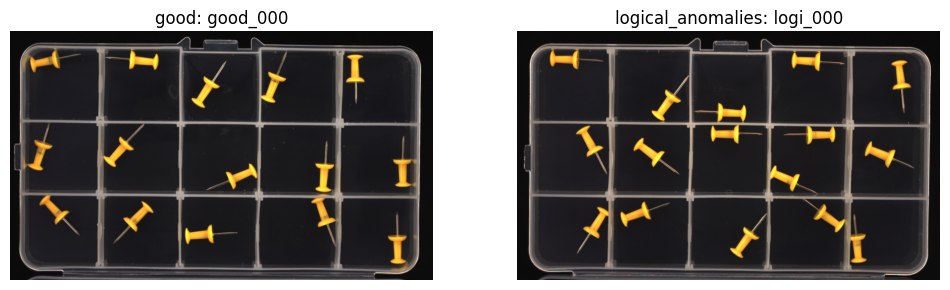

Check the layout matches the rule text below (compartment grid) before running.


In [5]:
from PIL import Image
def find_category_dir(root, category):
    """Locate the folder holding test/good and test/logical_anomalies, wherever the archive put it."""
    candidates = []
    for dirpath, dirnames, _ in os.walk(root):
        if os.path.isdir(os.path.join(dirpath, "test", "good")) and \
           os.path.isdir(os.path.join(dirpath, "test", "logical_anomalies")):
            candidates.append(dirpath)
    named = [c for c in candidates if os.path.basename(c) == category]
    return Path((named or candidates or [None])[0]) if (named or candidates) else None

if LOCO_DIR is None:
    EXTRACT_DIR = f"{WORK}/loco"
    CAT_DIR = find_category_dir(EXTRACT_DIR, CATEGORY) if os.path.isdir(EXTRACT_DIR) else None
    if CAT_DIR is None:
        archive = hf_hub_download(DATA_REPO, DATA_FILE, repo_type="dataset", token=HF_TOKEN,
                                  local_dir=f"{WORK}/downloads")
        os.makedirs(EXTRACT_DIR, exist_ok=True)
        subprocess.run(["tar", "-xJf", archive, "-C", EXTRACT_DIR], check=True)
        CAT_DIR = find_category_dir(EXTRACT_DIR, CATEGORY)
else:
    CAT_DIR = find_category_dir(LOCO_DIR, CATEGORY)
assert CAT_DIR is not None, "no folder with test/good and test/logical_anomalies found in the archive"
print("category folder:", CAT_DIR)

# Zero-shot protocol: only test images are used. No training or validation image is ever opened.
rows = []
for split, label in [("good", 0), ("logical_anomalies", 1)]:
    for p in sorted((CAT_DIR / "test" / split).glob("*.png")):
        rows.append(dict(img_id=f"{split[:4]}_{p.stem}", path=str(p), split=split, label=label))
images = pd.DataFrame(rows)
print(images.split.value_counts().to_dict())

def encode(path, max_side=IMAGE_MAX_SIDE):
    im = Image.open(path).convert("RGB")
    im.thumbnail((max_side, max_side))
    buf = io.BytesIO(); im.save(buf, format="JPEG", quality=92)
    return "data:image/jpeg;base64," + base64.b64encode(buf.getvalue()).decode()

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, split in zip(axes, ["good", "logical_anomalies"]):
    r = images[images.split == split].iloc[0]
    ax.imshow(Image.open(r.path)); ax.set_title(f"{split}: {r.img_id}"); ax.axis("off")
plt.show()
print("Check the layout matches the rule text below (compartment grid) before running.")


## Shared inspection logic (identical to the web app's `spec_core.py`)

In [6]:
# spec_core:
"""spec_core: shared logic for recording (Kaggle) and serving (Cloud Run).
Geometry (grid, walls) runs on an auto-gain copy of the image; the model sees the image as given."""
import io, base64, tempfile, time
import numpy as np
from PIL import Image, ImageDraw, ImageFont
from scipy import ndimage

ROWS, COLS = 3, 5
DIGITS = [str(d) for d in range(10)]
CELL_TEXT = ("The image is a close-up of a single compartment from a box of pushpins. How many pushpins are "
             "inside this compartment? Count a pushpin if its head is inside the compartment. "
             "Answer with a single digit only.")
SYSTEM = "You are a meticulous quality inspector on a packaging line. Look carefully at the image before answering."
WALL_DENSITY_MIN = 0.30     # good boxes' weakest wall line was >= 0.52; missing walls measured <= 0.10

# ---------------- grid geometry ----------------
def _smooth(p, k=9):
    return np.convolve(p, np.ones(k) / k, mode="same")

def _peaks(p, thr):
    idx = [i for i in range(1, len(p) - 1) if p[i] >= p[i - 1] and p[i] >= p[i + 1] and p[i] > thr]
    merged = []
    for i in idx:                                            # merge plateaus / near-duplicates
        if merged and i - merged[-1] < 15:
            if p[i] > p[merged[-1]]: merged[-1] = i
        else:
            merged.append(i)
    return merged

def _lines(profile, n_cells, strong=0.3, search=0.25):
    """Try every plausible (outer-left, outer-right) border pair among strong lines near the ends; keep the pair
    whose implied dividers are strongest and whose cells are most evenly sized (rejects lids/hinges/shadows)."""
    p = _smooth(profile)
    pk = _peaks(p, strong * p.max())
    span = pk[-1] - pk[0]
    los = [x for x in pk if x <= pk[0] + 0.25 * span]
    his = [x for x in pk if x >= pk[-1] - 0.25 * span]
    best = None
    for lo in los:
        for hi in his:
            if hi - lo < 0.5 * span:
                continue
            cell = (hi - lo) / n_cells
            inner = []
            for k in range(1, n_cells):
                c = lo + k * cell; w = int(search * cell)
                a, b = int(c - w), int(c + w)
                inner.append(a + int(np.argmax(p[a:b])))
            lines = [lo] + inner + [hi]
            widths = np.diff(lines)
            strength = float(np.mean([p[x] for x in inner]) / (p.max() + 1e-9))
            score = strength - 2.0 * widths.std() / widths.mean()
            if best is None or score > best[0]:
                best = (score, lines, strength)
    return best[1], best[2]

def find_grid(path, rows=ROWS, cols=COLS, sat_max=0.25, val_min=90):
    a = np.asarray(Image.open(path).convert("RGB")).astype(np.float32)
    mx, mn = a.max(-1), a.min(-1)
    wall = (mx > val_min) & ((mx - mn) / (mx + 1e-6) < sat_max)
    xs, sx = _lines(wall.mean(0), cols)
    ys, sy = _lines(wall.mean(1), rows)
    return xs, ys, min(sx, sy)

def cell_boxes(xs, ys, inset=6):
    return [(r, c, (xs[c] + inset, ys[r] + inset, xs[c + 1] - inset, ys[r + 1] - inset))
            for r in range(len(ys) - 1) for c in range(len(xs) - 1)]

def wall_box(xs, ys, orient, r, c, half=0.2, inset=10):
    """Strip centred on one internal wall segment, wide enough to show a bit of both neighbouring compartments."""
    if orient == "v":
        w = half * (xs[c + 1] - xs[c])
        return (int(xs[c + 1] - w), ys[r] + inset, int(xs[c + 1] + w), ys[r + 1] - inset)
    h = half * (ys[r + 1] - ys[r])
    return (xs[c] + inset, int(ys[r + 1] - h), xs[c + 1] - inset, int(ys[r + 1] + h))


def find_grid_image(im, rows=ROWS, cols=COLS):
    with tempfile.NamedTemporaryFile(suffix=".png") as f:
        im.save(f.name)
        return find_grid(f.name, rows=rows, cols=cols)

# ---------------- synthetic edits ----------------
PIN_HUES = {"Red": 0, "Green": 85, "Cyan": 128, "Blue": 165, "Purple": 195, "Pink": 225}   # PIL HSV hue (0-255)
COLOR_MODES = ["Original", *PIN_HUES, "Random per pin", "Cycle (changes every image)"]

def recolor(im, mode, seed=0):
    if mode == "Original":
        return im
    if mode.startswith("Cycle"):
        options = [*PIN_HUES, "Random per pin", "Original"]
        mode = options[seed % len(options)]
        if mode == "Original":
            return im
    hsv = np.array(im.convert("RGB").convert("HSV")).astype(np.int16)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    mask = (s > 110) & (v > 70)
    base = int(np.median(h[mask])) if mask.any() else 0
    if mode == "Random per pin":
        lab, n = ndimage.label(ndimage.binary_dilation(mask, iterations=3))
        rng = np.random.default_rng(seed)
        hues = np.array(list(PIN_HUES.values()) + [26])        # include the original yellow
        target = hues[rng.integers(0, len(hues), size=n + 1)]
        h[mask] = (h[mask] - base + target[lab[mask]]) % 256
    else:
        h[mask] = (h[mask] - base + PIN_HUES[mode]) % 256
    return Image.fromarray(np.stack([h, s, v], -1).astype(np.uint8), "HSV").convert("RGB")

def expose(im, stops):
    if not stops:
        return im
    a = np.asarray(im.convert("RGB")).astype(np.float32) * (2.0 ** float(stops))
    return Image.fromarray(np.clip(a, 0, 255).astype(np.uint8))

def normalize_for_geometry(im):
    a = np.asarray(im.convert("RGB")).astype(np.float32)
    p = np.percentile(a.max(-1), 99.5)
    return Image.fromarray(np.clip(a * (230.0 / max(p, 1.0)), 0, 255).astype(np.uint8))

def wall_strength(im, xs, ys, orient, r, c):
    a = np.asarray(im.crop(wall_box(xs, ys, orient, r, c))).astype(np.float32)
    mx, mn = a.max(-1), a.min(-1)
    wall = (mx > 90) & ((mx - mn) / (mx + 1e-6) < 0.25)
    return float(wall.mean(axis=0 if orient == "v" else 1).max())

# ---------------- model answers ----------------
def answer_distribution(choice, answers):
    """Distribution over the answer set from token log-probabilities. If the backend returns no logprobs
    (some hosted APIs), fall back to the answer text with 0.9 confidence."""
    aset = set(answers)
    for step in (choice.get("logprobs") or {}).get("content") or []:
        if step["token"].strip().lower() in aset:
            lp = {}
            for t in step.get("top_logprobs", []):
                a = t["token"].strip().lower()
                if a in aset:
                    lp[a] = np.logaddexp(lp[a], t["logprob"]) if a in lp else t["logprob"]
            if lp:
                floor = min(lp.values()) - 2.0
                raw = np.array([lp.get(a, floor) for a in answers]); p = np.exp(raw - raw.max()); p /= p.sum()
                return dict(zip(answers, p.tolist()))
    text = ((choice.get("message") or {}).get("content") or "").strip().lower()
    for ch in text.split():
        ch = ch.strip(".,:;!")
        if ch in aset:
            rest = 0.1 / (len(answers) - 1)
            return {a: (0.9 if a == ch else rest) for a in answers}
    return None

def chat_body(crop, text, model="gemma"):
    buf = io.BytesIO(); crop.convert("RGB").save(buf, format="JPEG", quality=95)
    url = "data:image/jpeg;base64," + base64.b64encode(buf.getvalue()).decode()
    return {"model": model,
            "messages": [{"role": "system", "content": SYSTEM},
                         {"role": "user", "content": [{"type": "image_url", "image_url": {"url": url}},
                                                      {"type": "text", "text": text}]}],
            "max_tokens": 8, "temperature": 0, "logprobs": True, "top_logprobs": 20,
            "chat_template_kwargs": {"enable_thinking": False}}

# ---------------- analyse (needs a model) and render (CPU only) ----------------
def analyze(im, ask, cell_text=CELL_TEXT, rows=ROWS, cols=COLS, max_workers=4):
    """Run all checks once and return raw results. `ask(crop, text, answers) -> dist or None`."""
    from concurrent.futures import ThreadPoolExecutor
    im = im.convert("RGB"); rows, cols = int(rows), int(cols)
    geo = normalize_for_geometry(im)
    xs, ys, strength = find_grid_image(geo, rows, cols)
    cells = cell_boxes(xs, ys)
    with ThreadPoolExecutor(max_workers=max_workers) as ex:
        dists = list(ex.map(lambda b: ask(im.crop(b), cell_text, DIGITS), [b for _, _, b in cells]))
    walls = [("v", r, c) for r in range(rows) for c in range(cols - 1)] + \
            [("h", r, c) for r in range(rows - 1) for c in range(cols)]
    return dict(rows=rows, cols=cols, xs=[int(x) for x in xs], ys=[int(y) for y in ys], grid_strength=float(strength),
                cells=[dict(r=r, c=c, box=[int(v) for v in b], dist=d) for (r, c, b), d in zip(cells, dists)],
                walls=[dict(o=o, r=r, c=c, strength=wall_strength(geo, xs, ys, o, r, c)) for o, r, c in walls])

def _font(size=34):
    try:
        return ImageFont.truetype("/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf", size)
    except Exception:
        return ImageFont.load_default()

def render(im, raw, expected=1, threshold=0.5, check_walls=True):
    """Apply the rules to recorded/raw answers: returns (annotated image, verdict markdown, rows, failed)."""
    expected = int(expected); xs, ys = raw["xs"], raw["ys"]
    out = im.convert("RGB").copy(); d = ImageDraw.Draw(out); font = _font()
    findings, table = [], []
    for cell in raw["cells"]:
        p = cell["dist"]; r, c, b = cell["r"], cell["c"], cell["box"]
        count = max(p, key=p.get) if p else "?"
        viol = (1.0 - p.get(str(expected), 0.0)) if p else 1.0
        flagged = viol > threshold
        table.append(dict(check=f"compartment row {r+1}, col {c+1}", answer=count,
                          p_violation=round(viol, 3), flagged=flagged))
        if flagged:
            findings.append(f"Rule 1: compartment row {r+1}, column {c+1} looks like it has **{count}** "
                            f"pushpin(s), expected {expected} (P(violation) = {viol:.2f})")
        color = (230, 40, 40) if flagged else (60, 200, 90)
        d.rectangle(b, outline=color, width=8 if flagged else 3)
        d.text((b[0] + 10, b[1] + 6), str(count), fill=color, font=font)
    if check_walls:
        for w in raw["walls"]:
            o, r, c, s = w["o"], w["r"], w["c"], w["strength"]
            missing = s < WALL_DENSITY_MIN
            a, b2 = (f"row {r+1}, col {c+1}", f"row {r+1}, col {c+2}") if o == "v" else \
                    (f"row {r+1}, col {c+1}", f"row {r+2}, col {c+1}")
            table.append(dict(check=f"wall between {a} and {b2}", answer=f"line strength {s:.2f}",
                              p_violation=None, flagged=missing))
            if missing:
                findings.append(f"Rule 3: the wall between {a} and {b2} is **missing** (line strength {s:.2f})")
                if o == "v":
                    d.line([(xs[c + 1], ys[r]), (xs[c + 1], ys[r + 1])], fill=(255, 150, 0), width=14)
                else:
                    d.line([(xs[c], ys[r + 1]), (xs[c + 1], ys[r + 1])], fill=(255, 150, 0), width=14)
    failed = bool(findings)
    verdict = ("### FAIL\n" + "\n".join(f"- {f}" for f in findings)) if failed else "### PASS\nAll rules satisfied."
    return out, verdict, table, failed


In [7]:
def make_vision_args(model_path, mmproj_path, ctx):
    def builder(slot):
        return ["--model", model_path, "--mmproj", mmproj_path, "--n-gpu-layers", "-1",
                "--flash-attn", "on", "--ctx-size", str(ctx), "--parallel", "1", "--jinja", *EXTRA_ARGS]
    return builder

slots, port = [], 8000
for gpu in ["0", "1"]:
    for j in range(N_CHAT_PER_GPU):
        slots.append(ServerSlot(f"gpu{gpu}-{'abcd'[j]}", gpu, port, "chat")); port += 1

RESULT_DIR = f"{WORK}/results_{RUN_ID}"
orchestrator = GPUOrchestrator(
    config=OrchestratorConfig(llama_server=LLAMA_SERVER, log_dir=f"{WORK}/server_logs",
                              result_dir=RESULT_DIR, health_timeout=600, checkpoint_every=RECYCLE_EVERY),
    slots=slots,
    chat_args=make_vision_args(MODEL_PATH, MMPROJ_PATH, CTX_SIZE),
)
orchestrator.start_all()


Launching gpu0-a: GPU 0, port 8000, kind=chat; free VRAM before=14912 MiB
  gpu0-a ready; free VRAM after=10721 MiB
Launching gpu0-b: GPU 0, port 8001, kind=chat; free VRAM before=10721 MiB
  gpu0-b ready; free VRAM after=6533 MiB
Launching gpu1-a: GPU 1, port 8002, kind=chat; free VRAM before=14912 MiB
  gpu1-a ready; free VRAM after=10721 MiB
Launching gpu1-b: GPU 1, port 8003, kind=chat; free VRAM before=10721 MiB
  gpu1-b ready; free VRAM after=6533 MiB
[servers]
  gpu0-a: GPU 0, port 8000, chat, running
  gpu0-b: GPU 0, port 8001, chat, running
  gpu1-a: GPU 1, port 8002, chat, running
  gpu1-b: GPU 1, port 8003, chat, running


## Record

In [8]:
# ---- Record Gemma's answers for the replay page ----
import itertools, threading, tarfile, random
PORTS = [s.port for s in slots]
_rr, _lock = itertools.cycle(PORTS), threading.Lock()

def ask(crop, text, answers):
    with _lock:
        port = next(_rr)
    r = requests.post(f"http://127.0.0.1:{port}/v1/chat/completions", json=chat_body(crop, text), timeout=300)
    r.raise_for_status()
    return answer_distribution(r.json()["choices"][0], answers)

# Which images and which synthetic variants to record
N_GOOD, N_BAD = 20, 20
MUST_INCLUDE = ["logi_067", "logi_062", "logi_080", "logi_064", "logi_076"]   # the missing-wall examples
VARIANTS = [("Original", 0.0), ("Blue", 0.0), ("Random per pin", 0.0),
            ("Red", -1.5), ("Original", -1.5), ("Purple", 1.0)]

rng = random.Random(11)
good = list(images[images.label == 0].img_id); bad = list(images[images.label == 1].img_id)
must = [i for i in MUST_INCLUDE if i in bad]
rest = [b for b in bad if b not in must]
pick_bad = must + rng.sample(rest, min(len(rest), max(0, N_BAD - len(must))))
pick_good = rng.sample(good, min(N_GOOD, len(good)))
LABEL = images.set_index("img_id").label.to_dict(); PATHS = images.set_index("img_id").path.to_dict()

# Sanity check before the long run: one good box, all 15 compartments must parse and should mostly read "1".
_probe = analyze(Image.open(PATHS[pick_good[0]]).convert("RGB"), ask, max_workers=len(PORTS))
_counts = [max(c["dist"], key=c["dist"].get) if c["dist"] else "?" for c in _probe["cells"]]
print("probe on a good box, counts per compartment:")
for r in range(3): print("   ", " ".join(_counts[r * 5:(r + 1) * 5]))
assert _counts.count("?") == 0, "some answers did not parse: check the server flags (thinking must be off)"

REPLAY = Path(f"{WORK}/replay"); (REPLAY / "images").mkdir(parents=True, exist_ok=True); (REPLAY / "entries").mkdir(exist_ok=True)
entries = [(i, col, st) for i in pick_good + pick_bad for col, st in VARIANTS]
entry_id = lambda i, col, st: f"{i}__{col.replace(' ', '-')}__{st:+.1f}"
print(f"recording {len(entries)} entries ({len(pick_good)} good + {len(pick_bad)} anomalous images x {len(VARIANTS)} variants)")

t0 = time.time()
for k, (i, col, st) in enumerate(entries):
    eid = entry_id(i, col, st); jpath = REPLAY / "entries" / f"{eid}.json"
    if jpath.exists():
        continue                                                     # resumable
    im = expose(recolor(Image.open(PATHS[i]).convert("RGB"), col, seed=k), st)
    t_e = time.time()
    raw = analyze(im, ask, max_workers=len(PORTS))
    raw["seconds"] = round(time.time() - t_e, 3)                    # one box, all checks, end to end
    im.save(REPLAY / "images" / f"{eid}.jpg", quality=90)
    raw.update(entry=eid, img_id=i, label=int(LABEL[i]), color=col, stops=st)
    jpath.write_text(json.dumps(raw))
    if (k + 1) % 10 == 0:
        print(f"  {k+1}/{len(entries)} in {(time.time()-t0)/60:.1f} min")
print(f"done in {(time.time()-t0)/60:.1f} min")


probe on a good box, counts per compartment:
    1 1 1 1 1
    1 1 1 1 1
    1 1 1 1 1
recording 240 entries (20 good + 20 anomalous images x 6 variants)
  10/240 in 0.6 min
  20/240 in 1.2 min
  30/240 in 1.8 min
  40/240 in 2.4 min
  50/240 in 3.0 min
  60/240 in 3.6 min
  70/240 in 4.3 min
  80/240 in 4.9 min
  90/240 in 5.5 min
  100/240 in 6.1 min
  110/240 in 6.7 min
  120/240 in 7.4 min
  130/240 in 8.0 min
  140/240 in 8.6 min
  150/240 in 9.2 min
  160/240 in 9.9 min
  170/240 in 10.5 min
  180/240 in 11.1 min
  190/240 in 11.8 min
  200/240 in 12.4 min
  210/240 in 13.0 min
  220/240 in 13.6 min
  230/240 in 14.2 min
  240/240 in 14.9 min
done in 14.9 min


## Robustness across colour and lighting

In [9]:
# ---- Robustness across colour and lighting (from the recorded answers) ----
from sklearn.metrics import roc_auc_score
recs = [json.loads(p.read_text()) for p in sorted((REPLAY / "entries").glob("*.json"))]
def model_score(raw):        # rule 1 only: worst compartment, P(count != 1)
    return max((1 - c["dist"].get("1", 0.0)) if c["dist"] else 1.0 for c in raw["cells"])
def wall_flag(raw):          # rule 3: any wall line below the threshold
    return float(min(w["strength"] for w in raw["walls"]) < WALL_DENSITY_MIN)
rows = []
for (col, st), grp in itertools.groupby(sorted(recs, key=lambda r: (r["color"], r["stops"])), key=lambda r: (r["color"], r["stops"])):
    grp = list(grp); y = [r["label"] for r in grp]
    m = [model_score(r) for r in grp]; mw = [max(s, wall_flag(r)) for s, r in zip(m, grp)]
    rows.append(dict(colour=col, lighting_stops=st, images=len(grp),
                     auroc_model=round(roc_auc_score(y, m) * 100, 1), auroc_model_plus_walls=round(roc_auc_score(y, mw) * 100, 1)))
robust = pd.DataFrame(rows); robust


,colour,lighting_stops,images,auroc_model,auroc_model_plus_walls
0,Blue,0.0,40,80.0,100.0
1,Original,-1.5,40,85.0,100.0
2,Original,0.0,40,83.7,100.0
3,Purple,1.0,40,85.2,100.0
4,Random per pin,0.0,40,78.3,100.0
5,Red,-1.5,40,79.7,100.0


## Throughput on these GPUs
Real timing for the coverage slide. `boxes_in_flight = 1` is one clamping station (one box at a time);
higher values show the ceiling when the GPUs are kept fully busy.

In [10]:
# ---- Throughput: boxes per minute on these GPUs ----
# boxes_in_flight=1 is an indexing station (one box clamped at a time); more boxes in flight shows the ceiling
# when several boxes are analysed at once (e.g. parallel lanes sharing the GPUs).
from concurrent.futures import ThreadPoolExecutor
bench_imgs = [Image.open(PATHS[i]).convert("RGB") for i in (pick_good + pick_bad)[:24]]
def one_box(im):
    t = time.time(); analyze(im, ask, max_workers=len(PORTS)); return time.time() - t
analyze(bench_imgs[0], ask, max_workers=len(PORTS))                  # warm-up
rows = []
for inflight in [1, 2, 4]:
    t0 = time.time()
    with ThreadPoolExecutor(inflight) as ex:
        lat = list(ex.map(one_box, bench_imgs))
    wall = time.time() - t0
    rows.append(dict(boxes_in_flight=inflight, boxes=len(bench_imgs),
                     boxes_per_min=round(len(bench_imgs) / wall * 60, 1),
                     mean_latency_s=round(float(np.mean(lat)), 2), p95_latency_s=round(float(np.percentile(lat, 95)), 2)))
bench = pd.DataFrame(rows)
GPU_NAME = subprocess.run(["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"],
                          capture_output=True, text=True).stdout.strip().replace("\n", " + ")
rec_secs = [json.loads(p.read_text()).get("seconds") for p in (REPLAY / "entries").glob("*.json")]
rec_secs = [x for x in rec_secs if x]
print(f"{GPU_NAME} | {len(PORTS)} Gemma servers | recording: {len(rec_secs)} boxes, "
      f"median {np.median(rec_secs):.2f} s per box" if rec_secs else GPU_NAME)
bench


Tesla T4 + Tesla T4 | 4 Gemma servers | recording: 240 boxes, median 3.56 s per box


,boxes_in_flight,boxes,boxes_per_min,mean_latency_s,p95_latency_s
0,1,24,16.7,3.60,3.71
1,2,24,23.2,5.07,5.65
2,4,24,23.9,9.59,11.03


## Line coverage from the measured throughput

In [11]:
# ---- Line coverage from the measured throughput ----
# Typical manufacturer-rated speeds (units per minute), from public machine specifications.
LINES = [("Manual kitting cell", 0.4, 0.4), ("Case packer", 5, 20), ("Automated kitting / bagging", 35, 60),
         ("Tray filling line", 45, 120), ("Intermittent cartoner", 60, 150), ("Continuous cartoner", 100, 500)]
station = float(bench.loc[bench.boxes_in_flight == 1, "boxes_per_min"].iloc[0])   # one clamping station
ceiling = float(bench.boxes_per_min.max())                                         # GPUs fully used
def cov(rate, lo, hi):
    a, b = min(100, rate / hi * 100), min(100, rate / lo * 100)
    return f"{a:.0f}%" if round(a) == round(b) else f"{a:.0f}-{b:.0f}%"
coverage = pd.DataFrame([dict(line=n, rate_per_min=(f"{lo:g}" if lo == hi else f"{lo:g}-{hi:g}"),
                              one_station=cov(station, lo, hi), gpus_fully_used=cov(ceiling, lo, hi),
                              stations_for_100pct=int(np.ceil(hi / ceiling))) for n, lo, hi in LINES])
print(f"one station: {station:.1f} boxes/min | ceiling on these GPUs: {ceiling:.1f} boxes/min")
coverage


one station: 16.7 boxes/min | ceiling on these GPUs: 23.9 boxes/min


,line,rate_per_min,one_station,gpus_fully_used,stations_for_100pct
0,Manual kitting cell,0.4,100%,100%,1
1,Case packer,5-20,84-100%,100%,1
2,Automated kitting / bagging,35-60,28-48%,40-68%,3
3,Tray filling line,45-120,14-37%,20-53%,6
4,Intermittent cartoner,60-150,11-28%,16-40%,7
5,Continuous cartoner,100-500,3-17%,5-24%,21


## Bundle and upload

In [12]:
# ---- Bundle the recording and push it to the Hub (the Cloud Run web app is built from it) ----
index = dict(model=MODEL_FILE, recorded=datetime.datetime.now().isoformat(timespec="seconds"),
             cell_text=CELL_TEXT, variants=[list(v) for v in VARIANTS],
             gpu=globals().get("GPU_NAME"), servers=len(PORTS),
             benchmark=bench.to_dict("records") if "bench" in globals() else None,
             robustness=robust.to_dict("records") if "robust" in globals() else None,
             entries=[json.loads(p.read_text()) for p in sorted((REPLAY / "entries").glob("*.json"))])
(REPLAY / "index.json").write_text(json.dumps(index))
bundle = f"{WORK}/replay_bundle.tar.gz"
with tarfile.open(bundle, "w:gz") as tar:
    tar.add(REPLAY / "index.json", arcname="replay/index.json")
    tar.add(REPLAY / "images", arcname="replay/images")
for name, df in [("robustness", globals().get("robust")), ("throughput", globals().get("bench")), ("coverage", globals().get("coverage"))]:
    if df is not None:
        df.to_csv(f"{WORK}/{name}.csv", index=False)                  # for the slides
print("bundle:", bundle, f"{os.path.getsize(bundle)/1e6:.0f} MB, {len(index['entries'])} entries")
if HF_TOKEN:
    from huggingface_hub import HfApi
    api = HfApi(token=HF_TOKEN)
    api.create_repo(HF_REPO, repo_type="dataset", private=True, exist_ok=True)
    api.upload_file(path_or_fileobj=bundle, path_in_repo="replay_bundle.tar.gz", repo_id=HF_REPO, repo_type="dataset")
    print("uploaded to", HF_REPO)


bundle: /kaggle/working/replay_bundle.tar.gz 42 MB, 240 entries


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

uploaded to saiphyohein/loco-zeroshot


In [13]:
orchestrator.stop_all()   # free the GPUs

[cleanup] all servers stopped
